# 04 · Versiones candidatas y decisión (validación cruzada 2023–2024)

Segunda fase del protocolo. Cada versión candidata se ajusta con los 7 algoritmos (hiperparámetros con Optuna, en una partición propia) y se evalúa el **ensamble** en validación cruzada 5×5 estratificada por año × evento, **solo con 2023–2024**.

**Regla de decisión (registrada antes de ejecutar los modelos):**
1. La mejor versión es la de mayor AUC dentro de cosecha.
2. Cada versión se compara con la mejor con la diferencia pareada en las 25 particiones y la prueba t corregida de Nadeau y Bengio.
3. Una versión **no se distingue de la mejor** si el IC 95 % de esa diferencia incluye el 0.
4. Se elige la **más simple** entre las que no se distinguen de la mejor (la mejor incluida).

Scripts: `src/04a_versiones_cv.py` (ajuste y validación cruzada) y `src/04b_decision.py` (regla). Aquí se recalcula la regla desde las predicciones guardadas y se verifica que coincida con la decisión registrada.

In [1]:
import json, sys, importlib.util, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import protocolo as P
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", 200); pd.set_option("display.float_format", "{:,.4f}".format)
R, R25, DG = P.SALIDA, P.SALIDA / "reporte_2025", P.SALIDA / "diagnosticos"
leer = lambda r: pd.read_csv(r, encoding="utf-8-sig")
def script(nombre):
    spec = importlib.util.spec_from_file_location(nombre.replace(".py", ""), RAIZ / "src" / nombre)
    m = importlib.util.module_from_spec(spec); spec.loader.exec_module(m); return m
NOMBRE = {"C1_completo": "C1 · Completo (17)", "C2_seleccionado": "C2 · Seleccionado (12)",
          "C3_V2p": "C3 · Depurado (6)", "C4_V2p_compra": "C4 · C3 + compra fuera del depto. (7)",
          "C5_V3p": "C5 · C4 + frecuencia de ciudad + volumen del distribuidor (9)", "C6_V5p": "C6 · C5 + departamento (10)",
          "A_C3_con_sexo": "C3 + sexo (7)", "segmento": "Segmento actual"}

## 1. Versiones candidatas

In [2]:
pd.DataFrame([{"versión": NOMBRE[v], "variables": ", ".join(vs)} for v, vs in P.candidatas().items()])

,versión,variables
0,C1 · Completo (17),"edad, estado_civil, estrato, personas_a_cargo, nivel_estudio, independiente_informal, ciudad, zona_homologada, departamento, compra_fuera_depto, log_frec_ciudad, vol_distribuidor_rango, familia_mo..."
1,C3 · Depurado (6),"edad, estado_civil, ciudad, independiente_informal, nivel_estudio, familia_moto"
2,C4 · C3 + compra fuera del depto. (7),"edad, estado_civil, ciudad, independiente_informal, nivel_estudio, familia_moto, compra_fuera_depto"
3,C5 · C4 + frecuencia de ciudad + volumen del distribuidor (9),"edad, estado_civil, ciudad, independiente_informal, nivel_estudio, familia_moto, compra_fuera_depto, log_frec_ciudad, vol_distribuidor_rango"
4,C6 · C5 + departamento (10),"edad, estado_civil, ciudad, independiente_informal, nivel_estudio, familia_moto, compra_fuera_depto, log_frec_ciudad, vol_distribuidor_rango, departamento"
5,C2 · Seleccionado (12),"edad, estado_civil, estrato, zona_homologada, departamento, compra_fuera_depto, log_frec_ciudad, familia_moto, tipo_uso_moto, cilindraje, precio_moto, propietario_moto_cliente"


## 2. AUC dentro de cosecha en las 25 particiones y aplicación de la regla

,versión,n_variables,auc_intra_cosecha,de_pliegues,dif_vs_mejor,ic_inf,ic_sup,p,no distinguible de la mejor,elegida
5,C2 · Seleccionado (12),12,0.6473,0.0351,0.0000,0.0000,0.0000,1.0000,True,False
0,C1 · Completo (17),17,0.6418,0.0332,-0.0056,-0.0145,0.0034,0.2125,True,False
4,C6 · C5 + departamento (10),10,0.6413,0.0362,-0.0060,-0.0196,0.0075,0.3668,True,False
2,C4 · C3 + compra fuera del depto. (7),7,0.6379,0.0368,-0.0094,-0.0270,0.0081,0.2791,True,False
3,C5 · C4 + frecuencia de ciudad + volumen del distribuidor (9),9,0.6371,0.0364,-0.0103,-0.0256,0.0050,0.1778,True,False
1,C3 · Depurado (6),6,0.6368,0.0346,-0.0105,-0.0287,0.0077,0.2460,True,True


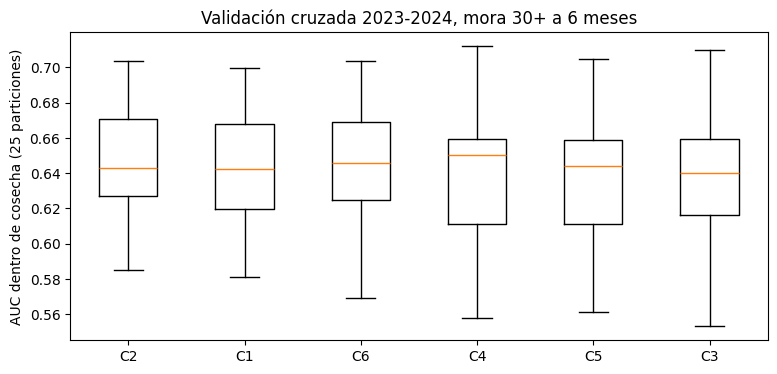

In [3]:
seleccion = script("04b_decision.py")
tabla, A = seleccion.tabla(list(P.candidatas()), P.ETIQUETA)
tabla["elegida"] = tabla.version == seleccion.elegir(tabla)
vista = tabla.assign(versión=tabla.version.map(NOMBRE)).sort_values("auc_intra_cosecha", ascending=False)
display(vista[["versión", "n_variables", "auc_intra_cosecha", "de_pliegues", "dif_vs_mejor", "ic_inf", "ic_sup", "p", "no_distinguible_de_la_mejor", "elegida"]].rename(columns={"no_distinguible_de_la_mejor": "no distinguible de la mejor"}))
fig, ax = plt.subplots(figsize=(9, 4))
orden = vista.version.tolist()
ax.boxplot([A[v] for v in orden], tick_labels=[NOMBRE[v].split(" · ")[0] for v in orden])
ax.set(ylabel="AUC dentro de cosecha (25 particiones)", title="Validación cruzada 2023-2024, mora 30+ a 6 meses")
plt.show()

In [4]:
decision = json.loads(P.DECISION.read_text(encoding="utf-8"))
assert decision["version"] == tabla.loc[tabla.elegida, "version"].iloc[0], "la decisión registrada no coincide"
print("OK: la regla recalculada coincide con la decisión registrada el", decision["fecha"])
print(json.dumps({k: decision[k] for k in ["fecha", "version", "variables", "etiqueta_principal"]}, indent=2, ensure_ascii=False))

OK: la regla recalculada coincide con la decisión registrada el 2026-10-27T21:33:01
{
  "fecha": "2026-10-27T21:33:01",
  "version": "C3_V2p",
  "variables": [
    "edad",
    "estado_civil",
    "ciudad",
    "independiente_informal",
    "nivel_estudio",
    "familia_moto"
  ],
  "etiqueta_principal": "B_todos"
}


**Lectura:**
- La mejor versión en validación cruzada es **C2** (12 variables, AUC dentro de cosecha 0,647), pero ninguna de las demás se distingue de ella: sus diferencias van de −0,0056 a −0,0105, y los intervalos corregidos, como mucho, de −0,0287 a +0,0081.
- Con la regla registrada se elige la más simple: **C3, con 6 variables** (edad, estado civil, ciudad, independiente informal, nivel de estudio y familia de moto), con AUC dentro de cosecha 0,637.
- La decisión se toma con 30+ a 6 meses (los pagos anticipados cuentan como buenos pagadores), en validación cruzada dentro de 2023–2024 y sin mirar 2025.

## 3. Costo de excluir el sexo

In [5]:
leer(R / "ablacion_sexo.csv")

,cambio,auc_con_sexo,auc_sin,diferencia,ic_inf,ic_sup,p
0,quitar sexo,0.6377,0.6368,-0.0009,-0.0059,0.0041,0.7196


**Lectura** (C3 con y sin sexo, validación cruzada 2023–2024):
- **Quitar el sexo de C3** no cambia la discriminación de forma distinguible: −0,0009 [−0,0059; +0,0041], p = 0,72. Se deja fuera del modelo y se usa solo para auditar la equidad (notebooks 05 y 07).